## Homework 4

[Условие задания](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md)


In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

np.random.seed(1)

url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

target = "converted"
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = [
    "annual_income",
    "number_of_courses_viewed",
    "interaction_count",
    "lead_score",
]
features = categorical + numerical

df = pd.read_csv(url)
df.head()


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Подготовка данных


In [2]:
display(df[features].isna().sum())

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

assert not df[features + [target]].isna().any().any()

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train[target].values
y_val = df_val[target].values

df_train = df_train.drop(columns=[target])
df_val = df_val.drop(columns=[target])

display(pd.DataFrame({
    "part": ["train", "validation", "test"],
    "rows": [len(df_train), len(df_val), len(df_test)],
}))


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

,part,rows
0,train,3000
1,validation,1000
2,test,1000


## Question 1: ROC AUC признаков


In [3]:
scores_q1 = []

for column in numerical:
    score = roc_auc_score(y_train, df_train[column])
    inverted = score < 0.5
    adjusted_score = (
        roc_auc_score(y_train, -df_train[column]) if inverted else score
    )
    scores_q1.append({
        "feature": column,
        "original_auc": score,
        "inverted": inverted,
        "auc": adjusted_score,
    })

results_q1 = pd.DataFrame(scores_q1).sort_values("auc", ascending=False)
display(results_q1)

answer_q1 = results_q1.iloc[0]["feature"]
print("Answer Q1:", answer_q1)


,feature,original_auc,inverted,auc
3,lead_score,0.788225,False,0.788225
2,interaction_count,0.764920,False,0.764920
1,number_of_courses_viewed,0.722989,False,0.722989
0,annual_income,0.608198,False,0.608198


Answer Q1: lead_score


## Вспомогательные функции


In [4]:
def train_model(train_df, train_y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_df[features].to_dict(orient="records"))

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, train_y)
    return dv, model


def predict_probabilities(dv, model, check_df):
    X_check = dv.transform(check_df[features].to_dict(orient="records"))
    return model.predict_proba(X_check)[:, 1]


## Question 2: ROC AUC модели


In [5]:
dv, model = train_model(df_train, y_train, C=1.0)
y_pred = predict_probabilities(dv, model, df_val)

validation_auc = roc_auc_score(y_val, y_pred)
answer_q2 = round(validation_auc, 3)

print("Validation ROC AUC:", validation_auc)
print("Answer Q2:", answer_q2)


Validation ROC AUC: 0.7318222288173319
Answer Q2: 0.732


## Question 3: Precision и Recall


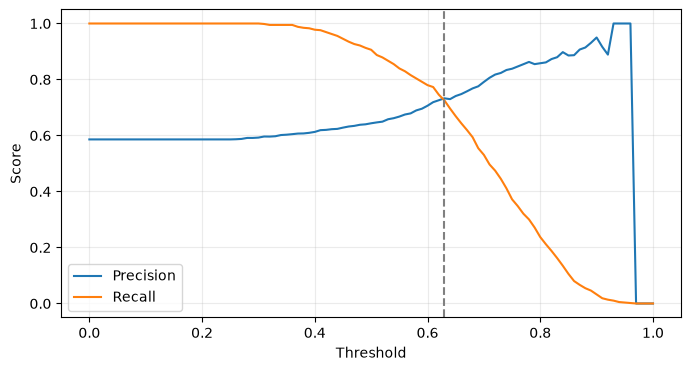

,threshold,precision,recall,f1,difference
63,0.63,0.732759,0.725256,0.728988,0.007503
62,0.62,0.725914,0.745734,0.735690,0.019820
64,0.64,0.729875,0.696246,0.712664,0.033629
61,0.61,0.719048,0.773038,0.745066,0.053990
65,0.65,0.741021,0.668942,0.703139,0.072079


Answer Q3: 0.63


In [6]:
thresholds = np.round(np.linspace(0.0, 1.0, 101), 2)
threshold_scores = []

for threshold in thresholds:
    predicted_class = y_pred >= threshold
    precision = precision_score(y_val, predicted_class, zero_division=0)
    recall = recall_score(y_val, predicted_class, zero_division=0)
    f1 = f1_score(y_val, predicted_class, zero_division=0)

    threshold_scores.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "difference": abs(precision - recall),
    })

threshold_results = pd.DataFrame(threshold_scores)

eligible = threshold_results[
    (threshold_results["precision"] > 0) | (threshold_results["recall"] > 0)
]
intersection = eligible.loc[eligible["difference"].idxmin()]
answer_q3 = float(intersection["threshold"])

plt.figure(figsize=(8, 4))
plt.plot(threshold_results["threshold"], threshold_results["precision"],
         label="Precision")
plt.plot(threshold_results["threshold"], threshold_results["recall"],
         label="Recall")
plt.axvline(answer_q3, color="gray", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

display(eligible.sort_values(["difference", "threshold"]).head())
print("Answer Q3:", answer_q3)


## Question 4: F1

$F_1 = 2PR / (P + R)$


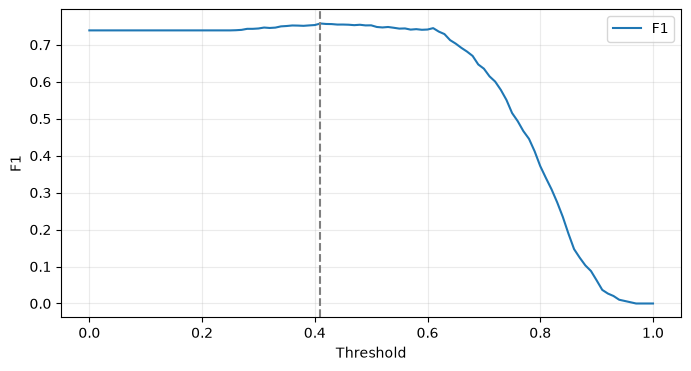

,threshold,precision,recall,f1,difference
41,0.41,0.619048,0.976109,0.757616,0.357062
42,0.42,0.620087,0.969283,0.756325,0.349196
43,0.43,0.622517,0.962457,0.756032,0.339941
45,0.45,0.628118,0.945392,0.754768,0.317275
44,0.44,0.623608,0.955631,0.754717,0.332023


Best F1: 0.7576158940397351
Answer Q4: 0.41


In [7]:
best_f1 = threshold_results.loc[threshold_results["f1"].idxmax()]
answer_q4 = float(best_f1["threshold"])

plt.figure(figsize=(8, 4))
plt.plot(threshold_results["threshold"], threshold_results["f1"], label="F1")
plt.axvline(answer_q4, color="gray", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

display(threshold_results.sort_values(
    ["f1", "threshold"], ascending=[False, True]
).head())
print("Best F1:", best_f1["f1"])
print("Answer Q4:", answer_q4)


## Question 5: 5-Fold CV


In [8]:
def cross_validation_scores(dataframe, C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(dataframe):
        fold_train = dataframe.iloc[train_idx]
        fold_val = dataframe.iloc[val_idx]

        dv_fold, model_fold = train_model(
            fold_train, fold_train[target].values, C=C
        )
        fold_predictions = predict_probabilities(dv_fold, model_fold, fold_val)
        score = roc_auc_score(fold_val[target].values, fold_predictions)
        scores.append(score)

    return np.array(scores)


cv_scores = cross_validation_scores(df_full_train, C=1.0)
display(pd.DataFrame({
    "fold": range(1, 6),
    "roc_auc": cv_scores,
}))

cv_mean = float(cv_scores.mean())
cv_std = float(cv_scores.std(ddof=0))
answer_q5 = round(cv_std, 3)

print("Mean ROC AUC:", cv_mean)
print("Standard deviation:", cv_std)
print("Answer Q5:", answer_q5)


,fold,roc_auc
0,1,0.730560
1,2,0.729573
2,3,0.736343
3,4,0.741245
4,5,0.720914


Mean ROC AUC: 0.7317269710972524
Standard deviation: 0.006853233151022138
Answer Q5: 0.007


## Question 6: подбор C


In [9]:
C_values = [0.000001, 0.001, 1]
scores_q6 = []

for C in C_values:
    scores = cv_scores if C == 1 else cross_validation_scores(df_full_train, C)
    scores_q6.append({
        "C": C,
        "mean_auc": float(scores.mean()),
        "std_auc": float(scores.std(ddof=0)),
        "mean rounded": round(float(scores.mean()), 3),
        "std rounded": round(float(scores.std(ddof=0)), 3),
    })

results_q6 = pd.DataFrame(scores_q6)
display(results_q6)

best_result = results_q6.sort_values(
    ["mean rounded", "std rounded", "C"],
    ascending=[False, True, True],
).iloc[0]
answer_q6 = float(best_result["C"])
print("Answer Q6:", format(answer_q6, ".6g"))


,C,mean_auc,std_auc,mean rounded,std rounded
0,0.000001,0.616734,0.018670,0.617,0.019
1,0.001000,0.749172,0.009996,0.749,0.010
2,1.000000,0.731727,0.006853,0.732,0.007


Answer Q6: 0.001


## Ответы


In [10]:
answers = pd.DataFrame({
    "question": ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    "answer": [
        answer_q1,
        answer_q2,
        answer_q3,
        answer_q4,
        answer_q5,
        format(answer_q6, ".6g"),
    ],
})
display(answers)

assert answer_q2 in [0.532, 0.632, 0.732, 0.832]
assert answer_q3 in [0.43, 0.63, 0.73, 0.83]
assert answer_q4 in [0.21, 0.41, 0.61, 0.81]
assert answer_q5 in [0.001, 0.007, 0.013, 0.060]
assert answer_q6 in C_values


,question,answer
0,Q1,lead_score
1,Q2,0.732
2,Q3,0.63
3,Q4,0.41
4,Q5,0.007
5,Q6,0.001
